# 🧠 Sesión 09-A: Transfer Learning — Feature Extraction

**Curso:** IS056B — Ingeniería del Conocimiento
**Docente:** Msc. Jaime Antonio Huaytalla Pariona
**Universidad:** UNCP — Facultad de Ingeniería de Sistemas
**Semestre:** 2026-II | **Unidad II:** Transferencia de Aprendizaje, Series de Tiempo y MLOps

---

### 🎯 Objetivos de este notebook
1. **Comprender** qué es Transfer Learning y por qué supera al entrenamiento desde cero
2. **Implementar** Feature Extraction con backbones pre-entrenados de Keras
3. **Practicar** con 3 ejemplos progresivos usando datasets públicos
4. **Visualizar** features transferidos y comparar rendimiento de diferentes backbones

### 📚 Estructura
| Ejemplo | Nivel | Dataset | Modelo Base | Enfoque |
|---------|-------|---------|-------------|---------|
| 1 | 🟢 Básico | Cats vs Dogs | MobileNetV2 | Primer Feature Extraction |
| 2 | 🟡 Intermedio | TF Flowers (5 clases) | EfficientNetB0 | EDA + Augmentation + Métricas |
| 3 | 🔴 Avanzado | Oxford-IIIT Pet (37 razas) | Comparación 4 backbones | Benchmark + t-SNE |

## ⚙️ Configuración del Entorno

Verificamos GPU disponible e instalamos dependencias.

In [1]:
# Verificar GPU
import subprocess
gpu_info = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total',
                          '--format=csv,noheader'], capture_output=True, text=True)
print("🖥️ GPU detectada:", gpu_info.stdout.strip() or "⚠️ No hay GPU — activa en Runtime > Change runtime type > T4 GPU")

🖥️ GPU detectada: Tesla T4, 15360 MiB


In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Configuración global
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

print(f"✅ TensorFlow {tf.__version__}")
print(f"✅ GPU disponible: {tf.config.list_physical_devices('GPU')}")

✅ TensorFlow 2.21.0
✅ GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
# 📖 Fundamentos de Transfer Learning

## ¿Qué es Transfer Learning?

> **Transferir conocimiento** de una tarea donde hay abundancia de datos (ej. ImageNet: 14M imágenes, 1000 clases) a una tarea donde tenemos pocos datos (nuestro problema específico).

### Analogía humana
Un músico que sabe tocar piano aprende guitarra más rápido que alguien que parte de cero. ¿Por qué? Porque ya tiene:
- Coordinación motora fina → **Features de bajo nivel** (bordes, texturas)
- Teoría musical → **Features de nivel medio** (patrones, formas)
- Sensibilidad rítmica → **Features de alto nivel** (estructuras complejas)

### ¿Por qué funciona en CNNs?
Las capas de una CNN entrenada en ImageNet aprenden features progresivamente más abstractos:

```
Capa 1-3:  Bordes, gradientes, colores      → UNIVERSALES (útiles para cualquier imagen)
Capa 4-7:  Texturas, patrones repetitivos   → SEMI-UNIVERSALES
Capa 8-12: Partes de objetos (ojos, ruedas) → SEMI-ESPECÍFICOS
Capa 13+:  Objetos completos (gato, auto)   → ESPECÍFICOS de ImageNet
```

### Feature Extraction (lo que hacemos hoy)
1. Tomamos un modelo pre-entrenado en ImageNet
2. **Congelamos** todo su backbone (las capas que extraen features)
3. Removemos su clasificador original (1000 clases)
4. Agregamos un **nuevo clasificador** para nuestras clases
5. Entrenamos **solo** el clasificador nuevo

> 💡 Es como comprar un telescopio profesional (backbone) y solo cambiarle el ocular (clasificador) para nuestra necesidad específica.

---
# 🟢 Ejemplo 1 — Básico: Cats vs Dogs con MobileNetV2

**Objetivo:** Primer contacto con Feature Extraction. Clasificación binaria (gato vs perro) usando MobileNetV2 pre-entrenado en ImageNet.

**Dataset:** [Cats vs Dogs](https://www.tensorflow.org/datasets/catalog/cats_vs_dogs) — ~25,000 imágenes de gatos y perros.

**¿Por qué MobileNetV2?** Es ligero (~3.4M parámetros), rápido y perfecto para empezar.

### 1.1. Cargar y explorar el dataset

In [3]:
!pip install -q importlib-resources

# Cargar Cats vs Dogs desde TensorFlow Datasets
(train_raw, val_raw), info = tfds.load(
    'cats_vs_dogs',
    split=['train[:80%]', 'train[80%:]'],  # No tiene split de test oficial
    as_supervised=True,
    with_info=True
)

NUM_CLASSES_1 = info.features['label'].num_classes
CLASS_NAMES_1 = info.features['label'].names
print(f"📊 Clases: {CLASS_NAMES_1}")
print(f"📊 Train: {tf.data.experimental.cardinality(train_raw).numpy():,} imágenes")
print(f"📊 Val:   {tf.data.experimental.cardinality(val_raw).numpy():,} imágenes")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.YALURA_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
📊 Clases: ['cat', 'dog']
📊 Train: 18,610 imágenes
📊 Val:   4,652 imágenes


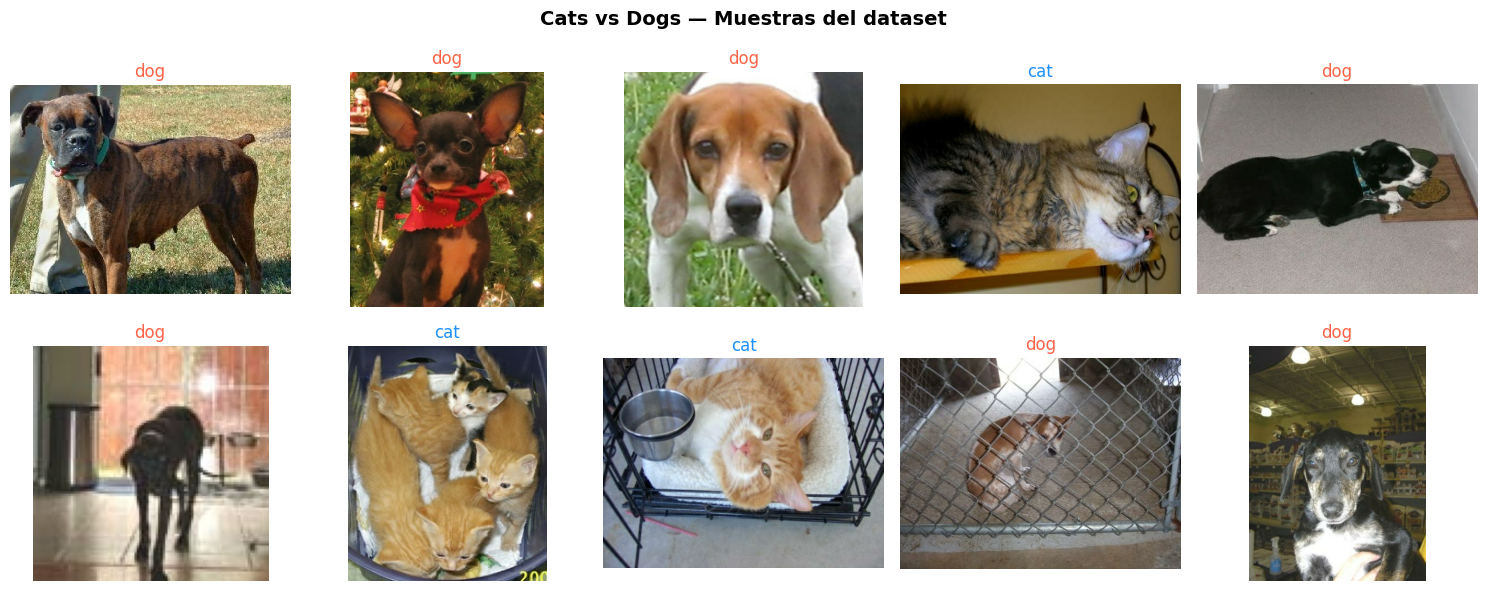

In [4]:
# Visualizar muestras
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, (img, label) in enumerate(train_raw.take(10)):
    ax = axes[i // 5, i % 5]
    ax.imshow(img.numpy())
    ax.set_title(CLASS_NAMES_1[label.numpy()], fontsize=12,
                color='dodgerblue' if label.numpy() == 0 else 'tomato')
    ax.axis('off')
plt.suptitle('Cats vs Dogs — Muestras del dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 1.2. Preprocesamiento

MobileNetV2 espera imágenes de **224×224** píxeles. Cada modelo tiene su propio `preprocess_input` que normaliza los píxeles al rango que usó durante su entrenamiento en ImageNet.

In [5]:
IMG_SIZE_1 = (224, 224)
BATCH_SIZE = 32

# Función de preprocesamiento
def preprocess_example1(image, label):
    image = tf.image.resize(image, IMG_SIZE_1)
    # MobileNetV2 espera píxeles en [-1, 1]
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES_1)
    return image, label

# Crear pipelines
train_ds_1 = (train_raw
    .map(preprocess_example1, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE))

val_ds_1 = (val_raw
    .map(preprocess_example1, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE))

# Verificar un batch
for imgs, labels in train_ds_1.take(1):
    print(f"✅ Batch shape: {imgs.shape}")
    print(f"✅ Labels shape: {labels.shape}")
    print(f"✅ Rango de píxeles: [{imgs.numpy().min():.2f}, {imgs.numpy().max():.2f}]")

✅ Batch shape: (32, 224, 224, 3)
✅ Labels shape: (32, 2)
✅ Rango de píxeles: [-1.00, 1.00]


### 1.3. Construir modelo con Feature Extraction

**Pasos clave:**
1. Cargar MobileNetV2 **sin** el clasificador (`include_top=False`)
2. **Congelar** todas sus capas (`trainable = False`)
3. Agregar nuestro clasificador binario

In [6]:
from tensorflow.keras import layers, models

# 1. Cargar backbone pre-entrenado (SIN clasificador de ImageNet)
base_model_1 = tf.keras.applications.MobileNetV2(
    weights='imagenet',       # Pesos entrenados en ImageNet
    include_top=False,        # Removemos las capas Dense de 1000 clases
    input_shape=(*IMG_SIZE_1, 3)
)

# 2. CONGELAR todo el backbone
base_model_1.trainable = False

print(f"📐 Backbone: MobileNetV2")
print(f"📐 Capas totales: {len(base_model_1.layers)}")
print(f"📐 Parámetros totales: {base_model_1.count_params():,}")
print(f"📐 Parámetros entrenables: 0  (todo congelado)")
print(f"📐 Output shape: {base_model_1.output_shape}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
📐 Backbone: MobileNetV2
📐 Capas totales: 154
📐 Parámetros totales: 2,257,984
📐 Parámetros entrenables: 0  (todo congelado)
📐 Output shape: (None, 7, 7, 1280)


In [7]:
# 3. Construir modelo completo: backbone + nuevo clasificador
model_1 = models.Sequential([
    # Backbone congelado
    base_model_1,
    # Nuevo clasificador
    layers.GlobalAveragePooling2D(),     # Reduce 7×7×1280 → 1280
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES_1, activation='softmax')
], name='catdog_mobilenetv2_FE')

model_1.summary()

# Contar parámetros
total = model_1.count_params()
trainable = sum(tf.size(w).numpy() for w in model_1.trainable_weights)
print(f"\n🔢 Total: {total:,} parámetros")
print(f"🔓 Entrenables: {trainable:,} ({trainable/total*100:.2f}%)")
print(f"🔒 Congelados: {total - trainable:,} ({(total-trainable)/total*100:.2f}%)")

Model: "catdog_mobilenetv2_FE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


🔢 Total: 2,260,546 parámetros
🔓 Entrenables: 2,562 (0.11%)
🔒 Congelados: 2,257,984 (99.89%)


> 💡 **Observa:** Solo ~2,560 parámetros son entrenables (el clasificador). Los ~2.2M del backbone están congelados. ¡Esto es Feature Extraction!

### 1.4. Entrenar y evaluar

In [8]:
# Compilar
model_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Entrenar (pocas épocas porque Feature Extraction converge rápido)
history_1 = model_1.fit(
    train_ds_1,
    validation_data=val_ds_1,
    epochs=8,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=3, restore_best_weights=True)
    ]
)

print(f"\n🏆 Mejor val_accuracy: {max(history_1.history['val_accuracy']):.4f}")

Epoch 1/8
582/582 ━━━━━━━━━━━━━━━━━━━━ 78s 95ms/step - accuracy: 0.9778 - loss: 0.0632 - val_accuracy: 0.9882 - val_loss: 0.0338
Epoch 2/8
582/582 ━━━━━━━━━━━━━━━━━━━━ 42s 68ms/step - accuracy: 0.9872 - loss: 0.0373 - val_accuracy: 0.9895 - val_loss: 0.0320
Epoch 3/8
582/582 ━━━━━━━━━━━━━━━━━━━━ 42s 69ms/step - accuracy: 0.9876 - loss: 0.0346 - val_accuracy: 0.9882 - val_loss: 0.0329
Epoch 4/8
582/582 ━━━━━━━━━━━━━━━━━━━━ 42s 69ms/step - accuracy: 0.9893 - loss: 0.0310 - val_accuracy: 0.9893 - val_loss: 0.0319
Epoch 5/8
582/582 ━━━━━━━━━━━━━━━━━━━━ 82s 68ms/step - accuracy: 0.9893 - loss: 0.0324 - val_accuracy: 0.9888 - val_loss: 0.0349
Epoch 6/8
582/582 ━━━━━━━━━━━━━━━━━━━━ 43s 70ms/step - accuracy: 0.9892 - loss: 0.0317 - val_accuracy: 0.9890 - val_loss: 0.0334
Epoch 7/8
582/582 ━━━━━━━━━━━━━━━━━━━━ 41s 68ms/step - accuracy: 0.9907 - loss: 0.0294 - val_accuracy: 0.9888 - val_loss: 0.0343

🏆 Mejor val_accuracy: 0.9895


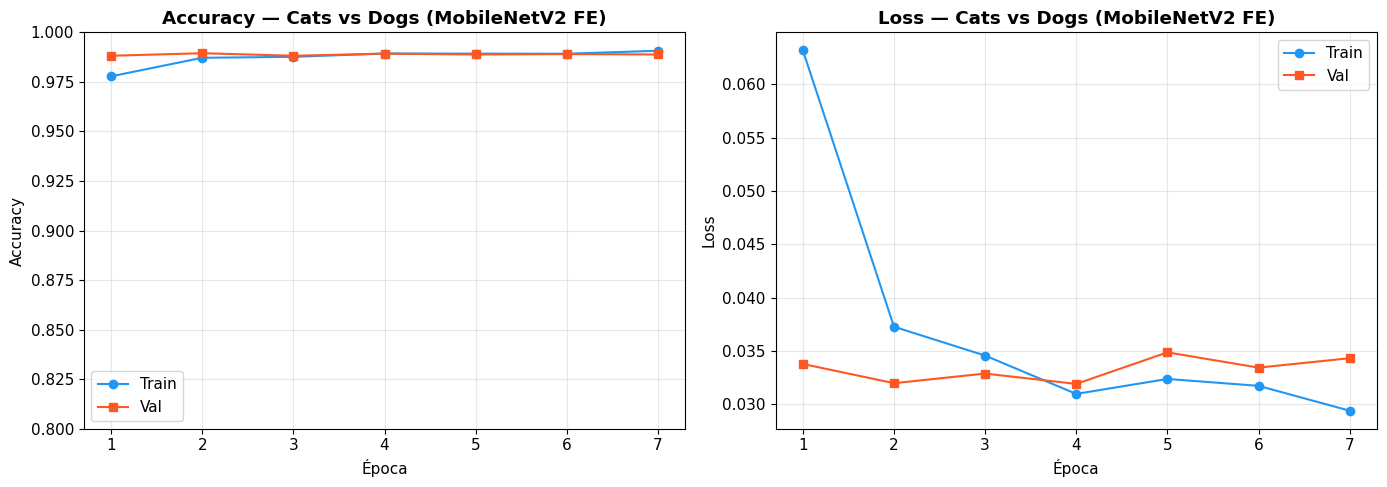

In [9]:
# Curvas de aprendizaje
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs = range(1, len(history_1.history['accuracy']) + 1)

axes[0].plot(epochs, history_1.history['accuracy'], 'o-', label='Train', color='#2196F3')
axes[0].plot(epochs, history_1.history['val_accuracy'], 's-', label='Val', color='#FF5722')
axes[0].set_title('Accuracy — Cats vs Dogs (MobileNetV2 FE)', fontweight='bold')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Accuracy')
axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0.8, 1.0])

axes[1].plot(epochs, history_1.history['loss'], 'o-', label='Train', color='#2196F3')
axes[1].plot(epochs, history_1.history['val_loss'], 's-', label='Val', color='#FF5722')
axes[1].set_title('Loss — Cats vs Dogs (MobileNetV2 FE)', fontweight='bold')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 1.5. Predicciones visuales

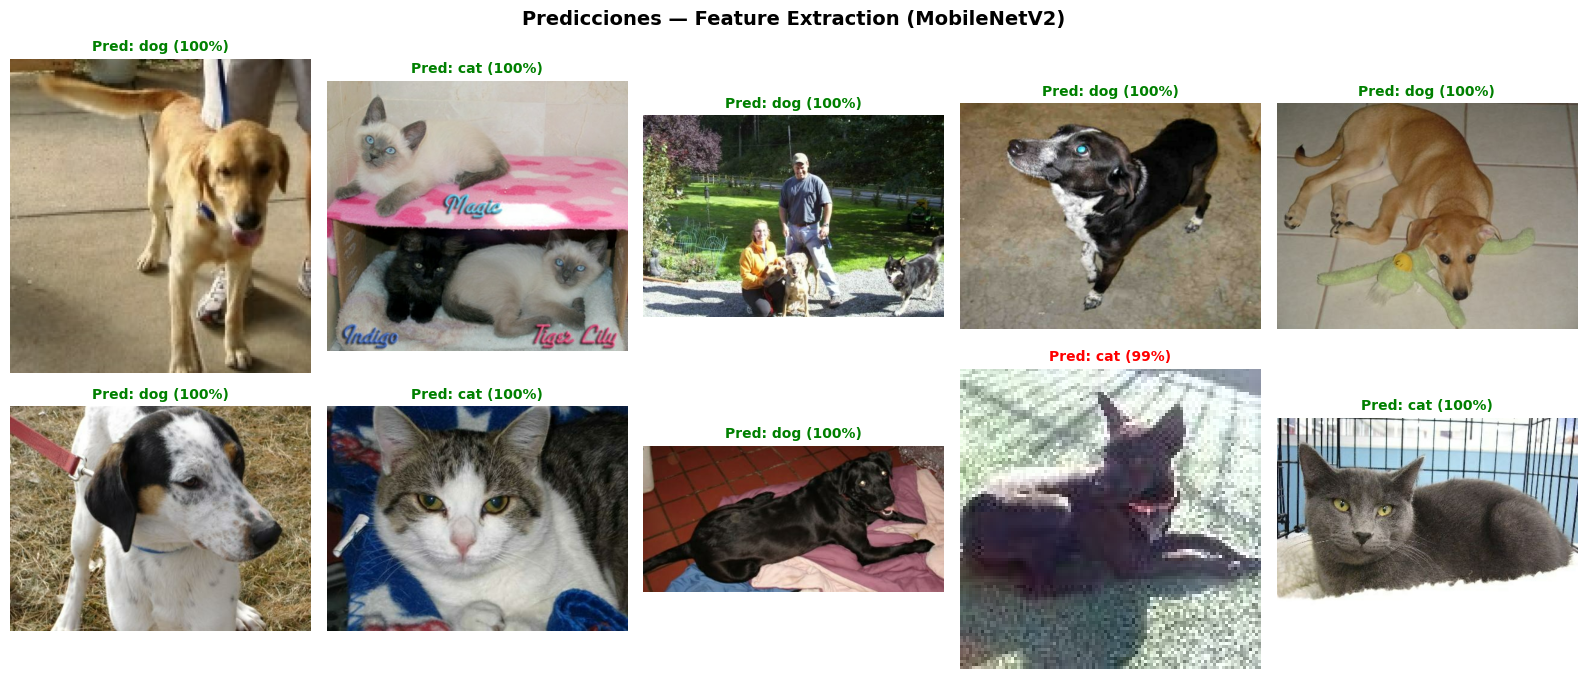

In [10]:
# Predecir sobre muestras de validación
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for i, (img, label) in enumerate(val_raw.take(10)):
    ax = axes[i // 5, i % 5]
    # Preprocesar para predicción
    img_prep = tf.image.resize(img, IMG_SIZE_1)
    img_prep = tf.keras.applications.mobilenet_v2.preprocess_input(
        tf.expand_dims(img_prep, 0))
    pred = model_1.predict(img_prep, verbose=0)
    pred_class = CLASS_NAMES_1[np.argmax(pred)]
    true_class = CLASS_NAMES_1[label.numpy()]
    correct = pred_class == true_class

    ax.imshow(img.numpy())
    ax.set_title(f"Pred: {pred_class} ({pred.max():.0%})",
                fontsize=10, color='green' if correct else 'red',
                fontweight='bold')
    ax.set_xlabel(f"Real: {true_class}", fontsize=9)
    ax.axis('off')

plt.suptitle('Predicciones — Feature Extraction (MobileNetV2)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### ✅ Conclusión Ejemplo 1

| Métrica | Valor |
|---------|-------|
| **Modelo base** | MobileNetV2 (2.2M params) |
| **Parámetros entrenados** | ~2,560 (solo el clasificador) |
| **Épocas** | ~5-8 |
| **Val Accuracy** | ~97%+ |
| **Tiempo aprox.** | <5 minutos en T4 |

> **Feature Extraction con MobileNetV2 logra ~97% de accuracy en pocos minutos**, clasificando gatos y perros sin entrenar millones de parámetros. Compara con una CNN desde cero que necesitaría mucho más tiempo y datos para alcanzar resultados similares.

---
# 🟡 Ejemplo 2 — Intermedio: TF Flowers con EfficientNetB0

**Objetivo:** Feature Extraction con 5 clases, EDA detallado, Data Augmentation, métricas avanzadas (confusion matrix, classification report) y visualización de feature maps.

**Dataset:** [TF Flowers](https://www.tensorflow.org/datasets/catalog/tf_flowers) — 3,670 fotos de 5 tipos de flores.

**¿Por qué EfficientNetB0?** Mejor balance accuracy/eficiencia de su generación. Un "upgrade" natural sobre MobileNetV2.

### 2.1. Cargar dataset y EDA

In [11]:
# Cargar TF Flowers
(train_raw_2, val_raw_2), info_2 = tfds.load(
    'tf_flowers',
    split=['train[:80%]', 'train[80%:]'],
    as_supervised=True,
    with_info=True
)

NUM_CLASSES_2 = info_2.features['label'].num_classes
CLASS_NAMES_2 = info_2.features['label'].names
print(f"🌸 Clases ({NUM_CLASSES_2}): {CLASS_NAMES_2}")
print(f"📊 Train: {tf.data.experimental.cardinality(train_raw_2).numpy():,}")
print(f"📊 Val:   {tf.data.experimental.cardinality(val_raw_2).numpy():,}")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.RDWMZ4_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
🌸 Clases (5): ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
📊 Train: 2,936
📊 Val:   734


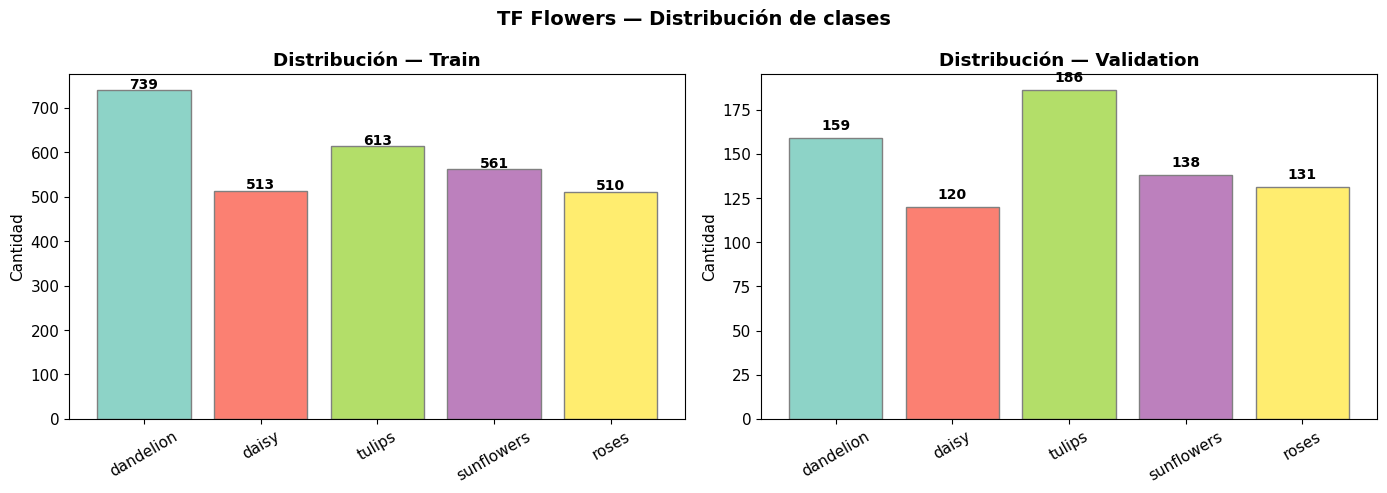

In [12]:
# Distribución de clases
train_labels = [label.numpy() for _, label in train_raw_2]
val_labels = [label.numpy() for _, label in val_raw_2]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, labels, title_str in [(axes[0], train_labels, 'Train'),
                               (axes[1], val_labels, 'Validation')]:
    unique, counts = np.unique(labels, return_counts=True)
    colors = plt.cm.Set3(np.linspace(0, 1, NUM_CLASSES_2))
    bars = ax.bar([CLASS_NAMES_2[u] for u in unique], counts, color=colors, edgecolor='gray')
    ax.set_title(f'Distribución — {title_str}', fontweight='bold')
    ax.set_ylabel('Cantidad')
    for bar, count in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
               str(count), ha='center', fontsize=10, fontweight='bold')
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('TF Flowers — Distribución de clases', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Muestras por clase
fig, axes = plt.subplots(NUM_CLASSES_2, 4, figsize=(14, 3 * NUM_CLASSES_2))
class_iterators = {i: iter(train_raw_2.filter(lambda x, y: y == i)) for i in range(NUM_CLASSES_2)}

for class_idx in range(NUM_CLASSES_2):
    for col in range(4):
        ax = axes[class_idx, col]
        try:
            img, _ = next(class_iterators[class_idx])
            ax.imshow(img.numpy())
        except StopIteration:
            pass
        ax.axis('off')
        if col == 0:
            ax.set_ylabel(CLASS_NAMES_2[class_idx], fontsize=12, fontweight='bold',
                         rotation=0, labelpad=60, va='center')

plt.suptitle('Muestras por clase — TF Flowers', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 2.2. Preprocesamiento con Data Augmentation

Para mejorar la generalización, aplicamos **Data Augmentation solo al conjunto de entrenamiento**. EfficientNet tiene su propio `preprocess_input` que escala los píxeles de forma particular.

In [14]:
IMG_SIZE_2 = (224, 224)

# Capa de augmentation (solo se aplica en entrenamiento)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
], name='augmentation')

def preprocess_train_2(image, label):
    image = tf.image.resize(image, IMG_SIZE_2)
    image = tf.cast(image, tf.float32)
    image = data_augmentation(image, training=True)
    image = tf.keras.applications.efficientnet.preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES_2)
    return image, label

def preprocess_val_2(image, label):
    image = tf.image.resize(image, IMG_SIZE_2)
    image = tf.keras.applications.efficientnet.preprocess_input(
        tf.cast(image, tf.float32))
    label = tf.one_hot(label, NUM_CLASSES_2)
    return image, label

train_ds_2 = (train_raw_2
    .map(preprocess_train_2, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000, seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

val_ds_2 = (val_raw_2
    .map(preprocess_val_2, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

print("✅ Pipelines listos con augmentation en train")

✅ Pipelines listos con augmentation en train


In [ ]:
# Visualizar augmentation
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
sample_img, sample_label = next(iter(train_raw_2))
sample_resized = tf.image.resize(tf.cast(sample_img, tf.float32), IMG_SIZE_2)

axes[0, 0].imshow(sample_img.numpy())
axes[0, 0].set_title('Original', fontweight='bold')
axes[0, 0].axis('off')

for i in range(1, 10):
    ax = axes[i // 5, i % 5]
    augmented = data_augmentation(tf.expand_dims(sample_resized, 0), training=True)
    ax.imshow(augmented[0].numpy().astype('uint8'))
    ax.set_title(f'Augmented #{i}', fontsize=10)
    ax.axis('off')

plt.suptitle(f'Data Augmentation — {CLASS_NAMES_2[sample_label.numpy()]}',
            fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.3. Construir modelo con EfficientNetB0

In [16]:
# Backbone EfficientNetB0
base_model_2 = tf.keras.applications.EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(*IMG_SIZE_2, 3)
)
base_model_2.trainable = False  # Congelar

# Modelo con clasificador más robusto
inputs_2 = layers.Input(shape=(*IMG_SIZE_2, 3))
x = base_model_2(inputs_2, training=False)  # BN en modo inferencia
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.2)(x)
outputs_2 = layers.Dense(NUM_CLASSES_2, activation='softmax')(x)

model_2 = models.Model(inputs_2, outputs_2, name='flowers_efficientnetb0_FE')

# Resumen
total = model_2.count_params()
trainable = sum(tf.size(w).numpy() for w in model_2.trainable_weights)
print(f"📐 EfficientNetB0 — Feature Extraction")
print(f"🔢 Total: {total:,} | 🔓 Entrenables: {trainable:,} | 🔒 Congelados: {total-trainable:,}")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
📐 EfficientNetB0 — Feature Extraction
🔢 Total: 4,219,304 | 🔓 Entrenables: 167,173 | 🔒 Congelados: 4,052,131


### 2.4. Entrenar con callbacks profesionales

In [ ]:
model_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_2 = model_2.fit(
    train_ds_2,
    validation_data=val_ds_2,
    epochs=15,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=5, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    ]
)

print(f"\n🏆 Mejor val_accuracy: {max(history_2.history['val_accuracy']):.4f}")

Epoch 1/15


In [ ]:
# Curvas de aprendizaje
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ep = range(1, len(history_2.history['accuracy']) + 1)
axes[0].plot(ep, history_2.history['accuracy'], 'o-', label='Train', color='#4CAF50')
axes[0].plot(ep, history_2.history['val_accuracy'], 's-', label='Val', color='#E91E63')
axes[0].set_title('Accuracy — TF Flowers (EfficientNetB0 FE)', fontweight='bold')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Accuracy')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep, history_2.history['loss'], 'o-', label='Train', color='#4CAF50')
axes[1].plot(ep, history_2.history['val_loss'], 's-', label='Val', color='#E91E63')
axes[1].set_title('Loss — TF Flowers (EfficientNetB0 FE)', fontweight='bold')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2.5. Evaluación detallada: Confusion Matrix + Classification Report

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Obtener predicciones
y_true, y_pred = [], []
for images, labels in val_ds_2:
    preds = model_2.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels.numpy(), axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Classification Report
print("📊 Classification Report — TF Flowers (EfficientNetB0 FE)")
print("=" * 65)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES_2, digits=4))

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=CLASS_NAMES_2, yticklabels=CLASS_NAMES_2, ax=ax,
           linewidths=0.5, linecolor='white',
           annot_kws={'size': 14, 'fontweight': 'bold'})

ax.set_xlabel('Predicción', fontsize=13, fontweight='bold')
ax.set_ylabel('Real', fontsize=13, fontweight='bold')
ax.set_title('Confusion Matrix — TF Flowers (EfficientNetB0 FE)',
            fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Top errores
print("\n🔍 Principales confusiones:")
for i in range(NUM_CLASSES_2):
    for j in range(NUM_CLASSES_2):
        if i != j and cm[i, j] > 2:
            print(f"   {CLASS_NAMES_2[i]} → {CLASS_NAMES_2[j]}: {cm[i, j]} errores")

### 2.6. Visualización de Feature Maps

¿Qué "ve" el backbone EfficientNetB0 en nuestras flores? Extraemos los mapas de activación de capas clave.

In [ ]:
# Seleccionar capas para visualizar
layer_names = ['block2a_expand_conv', 'block4a_expand_conv', 'block6a_expand_conv', 'top_conv']
feature_models = [
    models.Model(inputs=base_model_2.input,
                outputs=base_model_2.get_layer(name).output)
    for name in layer_names
]

# Tomar una imagen de ejemplo
sample_img_raw, sample_label_raw = next(iter(val_raw_2))
sample_processed = tf.image.resize(tf.cast(sample_img_raw, tf.float32), IMG_SIZE_2)
sample_processed = tf.keras.applications.efficientnet.preprocess_input(
    tf.expand_dims(sample_processed, 0))

# Extraer features
fig, axes = plt.subplots(len(layer_names), 9, figsize=(18, 2.5 * len(layer_names)))

for row, (feat_model, layer_name) in enumerate(zip(feature_models, layer_names)):
    features = feat_model.predict(sample_processed, verbose=0)
    # Mostrar la imagen original en la primera columna
    axes[row, 0].imshow(sample_img_raw.numpy())
    axes[row, 0].set_title('Original' if row == 0 else '', fontsize=9)
    axes[row, 0].set_ylabel(layer_name.replace('_', '\n'), fontsize=9,
                           fontweight='bold', rotation=0, labelpad=60, va='center')
    axes[row, 0].axis('off')
    # Mostrar 8 feature maps
    for col in range(1, 9):
        ax = axes[row, col]
        if col - 1 < features.shape[-1]:
            ax.imshow(features[0, :, :, col - 1], cmap='viridis')
        ax.axis('off')
        if row == 0:
            ax.set_title(f'Ch {col}', fontsize=9)

plt.suptitle(f'Feature Maps por Capa — {CLASS_NAMES_2[sample_label_raw.numpy()]}',
            fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

> 📝 **Observa la progresión**: las capas tempranas detectan bordes y texturas, las intermedias patrones más complejos (pétalos, tallos), y las profundas abstracciones de alto nivel. Estos features "universales" son lo que transfiere ImageNet a nuestras flores.

### ✅ Conclusión Ejemplo 2

| Métrica | Valor |
|---------|-------|
| **Modelo base** | EfficientNetB0 (4M params backbone) |
| **Parámetros entrenados** | ~17K (head) |
| **Val Accuracy** | ~88-92% (con solo 3,670 imágenes) |
| **Augmentation** | Flip + Rotation + Zoom + Contrast |
| **Métricas** | Confusion matrix + Classification report |
| **Visualización** | Feature maps por capa |

> Con solo ~3,700 imágenes y un head simple, EfficientNetB0 congelado alcanza excelentes resultados. Las flores más similares visualmente (tulips/roses) generan más confusiones.

---
# 🔴 Ejemplo 3 — Avanzado: Comparación de Backbones + t-SNE

**Objetivo:** Comparar 4 backbones distintos bajo las mismas condiciones para elegir el mejor para nuestro problema. Visualizar con t-SNE cómo los features transferidos separan las clases.

**Dataset:** Reutilizamos TF Flowers del Ejemplo 2 para comparar en igualdad de condiciones.

**Modelos a comparar:**
1. MobileNetV2 — Ligero, para dispositivos móviles
2. ResNet50 — Clásico, referencia de la industria
3. EfficientNetB0 — Balance accuracy/eficiencia
4. DenseNet121 — Conexiones densas, bueno con pocos datos

### 3.1. Función de benchmark

In [ ]:
import time

def benchmark_backbone(backbone_fn, preprocess_fn, backbone_name,
                       train_ds, val_ds, num_classes, img_size=(224, 224),
                       epochs=10):
    '''Entrena Feature Extraction con un backbone y retorna métricas.'''

    # Cargar backbone
    base = backbone_fn(weights='imagenet', include_top=False,
                       input_shape=(*img_size, 3))
    base.trainable = False

    # Construir modelo
    inp = layers.Input(shape=(*img_size, 3))
    x = base(inp, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(num_classes, activation='softmax')(x)
    model = models.Model(inp, out)

    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                 loss='categorical_crossentropy', metrics=['accuracy'])

    trainable_count = sum(tf.size(w).numpy() for w in model.trainable_weights)
    total_count = model.count_params()

    # Entrenar
    start_time = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=0,
                       callbacks=[tf.keras.callbacks.EarlyStopping(
                           monitor='val_loss', patience=4, restore_best_weights=True)])
    train_time = time.time() - start_time

    best_val_acc = max(history.history['val_accuracy'])
    best_epoch = history.history['val_accuracy'].index(best_val_acc) + 1

    return {
        'Backbone': backbone_name,
        'Params backbone': f"{base.count_params():,}",
        'Params entrenables': f"{trainable_count:,}",
        'Best Val Acc': f"{best_val_acc:.4f}",
        'Mejor época': best_epoch,
        'Tiempo (s)': f"{train_time:.0f}",
        'model': model,
        'history': history,
        'base_model': base,
    }

### 3.2. Preparar datasets con preprocesamiento genérico

Para comparar backbones que tienen diferentes `preprocess_input`, usamos un preprocesamiento unificado a [0, 255] y dejamos que cada backbone normalice internamente.

In [ ]:
# Dataset genérico (sin preprocess_input específico — cada backbone lo aplicará)
def preprocess_generic(image, label):
    image = tf.image.resize(image, (224, 224))
    image = tf.cast(image, tf.float32)  # [0, 255]
    label = tf.one_hot(label, NUM_CLASSES_2)
    return image, label

train_generic = (train_raw_2
    .map(preprocess_generic, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000, seed=SEED).batch(32).prefetch(tf.data.AUTOTUNE))
val_generic = (val_raw_2
    .map(preprocess_generic, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(32).prefetch(tf.data.AUTOTUNE))

print("✅ Datasets genéricos listos para benchmark")

### 3.3. Ejecutar benchmark con 4 backbones

> ⏱️ Esto tomará unos minutos. Cada modelo se entrena por 10 épocas máximo.

In [ ]:
backbones = [
    (tf.keras.applications.MobileNetV2, 'MobileNetV2'),
    (tf.keras.applications.ResNet50, 'ResNet50'),
    (tf.keras.applications.EfficientNetB0, 'EfficientNetB0'),
    (tf.keras.applications.DenseNet121, 'DenseNet121'),
]

results = []
for backbone_fn, name in backbones:
    print(f"\n{'='*50}")
    print(f"🔄 Entrenando: {name}")
    print('='*50)
    result = benchmark_backbone(
        backbone_fn, None, name,
        train_generic, val_generic,
        NUM_CLASSES_2, epochs=10
    )
    results.append(result)
    print(f"   ✅ {name}: val_acc = {result['Best Val Acc']}, "
          f"tiempo = {result['Tiempo (s)']}s")

print("\n🏁 Benchmark completado!")

In [ ]:
# Tabla comparativa
df_results = pd.DataFrame([{k: v for k, v in r.items()
                            if k not in ('model', 'history', 'base_model')}
                           for r in results])
print("\n📊 TABLA COMPARATIVA DE BACKBONES")
print("=" * 80)
print(df_results.to_string(index=False))

In [ ]:
# Gráfico comparativo
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['#FF6384', '#36A2EB', '#FFCE56', '#4BC0C0']

# 1. Val Accuracy por backbone
accs = [float(r['Best Val Acc']) for r in results]
names = [r['Backbone'] for r in results]
bars = axes[0].bar(names, accs, color=colors, edgecolor='gray', alpha=0.85)
axes[0].set_title('Val Accuracy por Backbone', fontweight='bold')
axes[0].set_ylabel('Accuracy')
axes[0].set_ylim([min(accs) - 0.05, max(accs) + 0.03])
for bar, acc in zip(bars, accs):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{acc:.3f}', ha='center', fontweight='bold', fontsize=11)
axes[0].grid(True, alpha=0.3, axis='y')

# 2. Tiempo de entrenamiento
times = [float(r['Tiempo (s)']) for r in results]
bars2 = axes[1].bar(names, times, color=colors, edgecolor='gray', alpha=0.85)
axes[1].set_title('Tiempo de entrenamiento (s)', fontweight='bold')
axes[1].set_ylabel('Segundos')
for bar, t in zip(bars2, times):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                f'{t:.0f}s', ha='center', fontweight='bold', fontsize=11)
axes[1].grid(True, alpha=0.3, axis='y')

# 3. Curvas de accuracy
for r, color in zip(results, colors):
    h = r['history']
    ep = range(1, len(h.history['val_accuracy']) + 1)
    axes[2].plot(ep, h.history['val_accuracy'], 'o-', label=r['Backbone'],
                color=color, linewidth=2)
axes[2].set_title('Val Accuracy por época', fontweight='bold')
axes[2].set_xlabel('Época'); axes[2].set_ylabel('Accuracy')
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.suptitle('Benchmark: Feature Extraction con 4 Backbones — TF Flowers',
            fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 3.4. Visualización t-SNE de features transferidos

**t-SNE** (t-distributed Stochastic Neighbor Embedding) nos permite visualizar cómo los features de alta dimensión del backbone separan las clases en 2D. Si los puntos de cada clase forman clusters separados, ¡Transfer Learning está funcionando!

In [ ]:
from sklearn.manifold import TSNE

def extract_features(model, dataset, max_samples=500):
    '''Extrae features del backbone (antes del clasificador).'''
    # Crear modelo que retorna la capa GAP
    feature_extractor = models.Model(
        inputs=model.input,
        outputs=model.layers[-5].output  # Antes de Dense/Dropout
    )
    features, labels = [], []
    count = 0
    for imgs, lbls in dataset:
        feats = feature_extractor.predict(imgs, verbose=0)
        features.append(feats)
        labels.append(np.argmax(lbls.numpy(), axis=1))
        count += imgs.shape[0]
        if count >= max_samples:
            break
    return np.concatenate(features)[:max_samples], np.concatenate(labels)[:max_samples]

# Extraer features del mejor modelo
best_idx = np.argmax([float(r['Best Val Acc']) for r in results])
best_model = results[best_idx]['model']
best_name = results[best_idx]['Backbone']
print(f"📊 Extrayendo features de {best_name} (mejor backbone)...")

features, labels = extract_features(best_model, val_generic, max_samples=500)
print(f"✅ Features shape: {features.shape}")

In [ ]:
# Ejecutar t-SNE
print("🔄 Calculando t-SNE (esto toma ~30 segundos)...")
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30, n_iter=1000)
features_2d = tsne.fit_transform(features)

# Visualizar
fig, ax = plt.subplots(figsize=(10, 8))
scatter_colors = plt.cm.Set1(np.linspace(0, 0.8, NUM_CLASSES_2))

for class_idx in range(NUM_CLASSES_2):
    mask = labels == class_idx
    ax.scatter(features_2d[mask, 0], features_2d[mask, 1],
              c=[scatter_colors[class_idx]], label=CLASS_NAMES_2[class_idx],
              alpha=0.7, s=40, edgecolors='white', linewidths=0.5)

ax.set_title(f't-SNE de Features Transferidos — {best_name}\n'
            f'(cada punto = una imagen, color = clase)',
            fontsize=14, fontweight='bold')
ax.legend(fontsize=11, markerscale=1.5, loc='best')
ax.set_xlabel('t-SNE dim 1'); ax.set_ylabel('t-SNE dim 2')
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

print("\n💡 Clases que forman clusters separados → el backbone distingue bien sus features")
print("💡 Clases cuyos clusters se superponen → son visualmente similares (confusiones esperadas)")

### 3.5. Comparación t-SNE: Features aleatorios vs. Features transferidos

In [ ]:
# Comparar: features de un backbone con pesos ALEATORIOS vs pesos de IMAGENET
# Esto demuestra el valor de Transfer Learning

# Backbone con pesos aleatorios (sin Transfer Learning)
base_random = tf.keras.applications.EfficientNetB0(
    weights=None,  # ¡Pesos aleatorios!
    include_top=False,
    input_shape=(224, 224, 3)
)

# Extraer features con pesos aleatorios
random_features = []
random_labels = []
count = 0
for imgs, lbls in val_generic:
    feats = base_random.predict(imgs, verbose=0)
    feats = tf.keras.layers.GlobalAveragePooling2D()(feats).numpy()
    random_features.append(feats)
    random_labels.append(np.argmax(lbls.numpy(), axis=1))
    count += imgs.shape[0]
    if count >= 500:
        break

random_features = np.concatenate(random_features)[:500]
random_labels_arr = np.concatenate(random_labels)[:500]

# t-SNE de features aleatorios
tsne_random = TSNE(n_components=2, random_state=SEED, perplexity=30)
random_2d = tsne_random.fit_transform(random_features)

In [ ]:
# Visualización lado a lado
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, data, lab, title_str in [
    (axes[0], random_2d, random_labels_arr, 'Pesos ALEATORIOS (sin TL)'),
    (axes[1], features_2d, labels, f'Pesos IMAGENET ({best_name} TL)')
]:
    for class_idx in range(NUM_CLASSES_2):
        mask = lab == class_idx
        ax.scatter(data[mask, 0], data[mask, 1],
                  c=[scatter_colors[class_idx]], label=CLASS_NAMES_2[class_idx],
                  alpha=0.7, s=40, edgecolors='white', linewidths=0.5)
    ax.set_title(title_str, fontsize=13, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.2)

plt.suptitle('t-SNE: ¿Qué aporta Transfer Learning?\n'
            'Pesos aleatorios no separan clases — ImageNet sí',
            fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### ✅ Conclusión Ejemplo 3

**Hallazgos clave del benchmark:**
1. Los 4 backbones superan ampliamente a una CNN desde cero con este tamaño de dataset
2. EfficientNetB0 y DenseNet121 suelen liderar en accuracy
3. MobileNetV2 es el más rápido — ideal si hay restricciones de cómputo
4. ResNet50 es el más pesado pero no necesariamente el más preciso

**t-SNE demuestra visualmente:**
- Los features de ImageNet ya separan nuestras flores **sin entrenamiento adicional**
- Un backbone con pesos aleatorios produce features que NO distinguen clases
- Esta es la prueba visual de **por qué Transfer Learning funciona**

---
# 📋 Resumen de la Sesión 09-A

## Lo que aprendimos hoy

| Concepto | Descripción |
|----------|-------------|
| **Transfer Learning** | Reutilizar conocimiento de ImageNet para nuestro problema |
| **Feature Extraction** | Congelar backbone + entrenar solo clasificador nuevo |
| **`include_top=False`** | Remover las capas Dense originales de 1000 clases |
| **`trainable = False`** | Congelar todos los pesos del backbone |
| **`preprocess_input`** | Cada modelo tiene su propia normalización |
| **`training=False`** | Las capas BN usan estadísticos de ImageNet (estable) |
| **t-SNE** | Visualización de features de alta dimensión en 2D |

## Próximo paso: Sesión 09-B — Fine-Tuning

En Feature Extraction tratamos el backbone como caja negra. En **Fine-Tuning**, descongelaremos parte del backbone y lo re-entrenaremos con un learning rate bajo para **adaptar** los features a nuestro dominio → ¡mayor accuracy!

---
*IS056B — Ingeniería del Conocimiento | UNCP 2026-II | Msc. Jaime Huaytalla Pariona*